# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Khanum Nawra Attar
- **Email:** khanumattr@gmail.com
- **ID Dicoding:** khanumattr

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- Pertanyaan 1:
**Selama Januari–Desember 2017, bagaimana perubahan bulanan nilai penjualan produk (GMV, tidak termasuk ongkos kirim) dan jumlah pesanan yang telah berstatus delivered, serta bulan mana yang harus diprioritaskan untuk perencanaan stok dan promosi?**
- Pertanyaan 2:
**Selama Januari–Desember 2017, apa lima kategori produk dengan kontribusi GMV terbesar pada pesanan delivered, berapa persentase kontribusinya, dan bagaimana skor ulasan rata-ratanya untuk menentukan prioritas promosi serta perbaikan pengalaman pelanggan?**

## Import Semua Packages/Library yang Digunakan

In [13]:
from pathlib import Path
from zipfile import ZipFile
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

DATA_DIR = Path("data/raw")
OUTPUT_DIR = Path("data/processed")
FIG_DIR = Path("visualizations")
for folder in [DATA_DIR, OUTPUT_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## Data Wrangling

### Gathering Data

#### Load df E-Commerce Public Dataset

In [14]:
zip_files = glob.glob("*.zip")
if not zip_files:
    print("PERINGATAN: File zip dataset tidak ditemukan di direktori utama. Harap unggah file .zip dataset Anda ke Colab terlebih dahulu!")
else:
    zip_path = zip_files[0]
    print(f"Menemukan file zip: {zip_path}. Memulai ekstraksi 5 data utama...")

    target_files = [
        "orders_dataset.csv",
        "order_items_dataset.csv",
        "products_dataset.csv",
        "product_category_name_translation.csv",
        "order_reviews_dataset.csv"
    ]

    DATA_DIR.mkdir(parents=True, exist_ok=True)

    with ZipFile(zip_path, 'r') as zip_ref:
        for file in zip_ref.namelist():
            filename = Path(file).name
            if filename in target_files:
                target_path = DATA_DIR / filename
                with zip_ref.open(file) as source, open(target_path, "wb") as target:
                    shutil.copyfileobj(source, target)
                print(f"Berhasil mengekstrak: {filename} -> {target_path}")

orders_df = pd.read_csv(DATA_DIR / "orders_dataset.csv")
items_df = pd.read_csv(DATA_DIR / "order_items_dataset.csv")
products_df = pd.read_csv(DATA_DIR / "products_dataset.csv")
translations_df = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")
reviews_df = pd.read_csv(DATA_DIR / "order_reviews_dataset.csv")

for name, df in {
    "orders": orders_df,
    "items": items_df,
    "products": products_df,
    "translations": translations_df,
    "reviews": reviews_df
}.items():
    print(name, df.shape)

display(orders_df.head())
display(items_df.head())

Menemukan file zip: E-commerce-public-dataset.zip. Memulai ekstraksi 5 data utama...
Berhasil mengekstrak: order_items_dataset.csv -> data/raw/order_items_dataset.csv
Berhasil mengekstrak: order_reviews_dataset.csv -> data/raw/order_reviews_dataset.csv
Berhasil mengekstrak: orders_dataset.csv -> data/raw/orders_dataset.csv
Berhasil mengekstrak: product_category_name_translation.csv -> data/raw/product_category_name_translation.csv
Berhasil mengekstrak: products_dataset.csv -> data/raw/products_dataset.csv
orders (99441, 8)
items (112650, 7)
products (32951, 9)
translations (71, 2)
reviews (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**Insight:**
- Terdapat 5 Dataset yang berhasil diambil untuk dilakukan pengolahan dan menjawab pertanyaan.

### Assessing Data




#### Identifying Missing Values Problem

In [15]:
# Membaca dataset terlebih dahulu sebelum melakukan assessing
orders_df = pd.read_csv(DATA_DIR / "orders_dataset.csv")
items_df = pd.read_csv(DATA_DIR / "order_items_dataset.csv")
products_df = pd.read_csv(DATA_DIR / "products_dataset.csv")
translations_df = pd.read_csv(DATA_DIR / "product_category_name_translation.csv")
reviews_df = pd.read_csv(DATA_DIR / "order_reviews_dataset.csv")

datasets = {
    "orders": orders_df,
    "items": items_df,
    "products": products_df,
    "reviews": reviews_df
}

for name, df in datasets.items():
    print(f"\n=== {name.upper()} ===")
    print("Missing Values:")
    print(df.isna().sum())
    print("Duplikasi baris:", df.duplicated().sum())

print("\n=== KEJANGGALAN SPESIFIK ===")
print(
    "Kategori kosong:",
    products_df["product_category_name"].isna().sum()
)

print(
    "Order ID berulang pada review:",
    reviews_df["order_id"].duplicated().sum()
)

print(
    "Harga tidak positif:",
    (items_df["price"] <= 0).sum()
)


=== ORDERS ===
Missing Values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Duplikasi baris: 0

=== ITEMS ===
Missing Values:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Duplikasi baris: 0

=== PRODUCTS ===
Missing Values:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64
Duplikasi baris: 0

=== REVIEWS ===
Missi

**Steps to Take:**
- Menyaring pesanan dengan status delivered dan periode transaksi tahun 2017.
- Mengisi kategori produk yang kosong dengan Unknown.
- Mengelompokkan skor ulasan berdasarkan order_id menggunakan nilai rata-rata untuk menghindari penggandaan data saat penggabungan.
- Mempertahankan nilai kosong pada judul dan komentar ulasan karena analisis hanya menggunakan review_score.
- Memvalidasi harga produk dan ongkos kirim sebelum menggabungkan seluruh dataset.

**Insight:** (Opsional)
- xxx
- xxx

### Cleaning Data

#### Fixing Missing Values Problem

In [16]:
orders_df["order_purchase_timestamp"] = pd.to_datetime(
    orders_df["order_purchase_timestamp"],
    errors="coerce"
)

orders_2017 = orders_df[
    (orders_df["order_status"] == "delivered") &
    (
        orders_df["order_purchase_timestamp"].between(
            "2017-01-01", "2017-12-31 23:59:59"
        )
    )
][["order_id", "order_purchase_timestamp"]].copy()

items_clean = items_df[
    (items_df["price"] > 0) &
    (items_df["freight_value"] >= 0)
].copy()

reviews_clean = reviews_df[
    ["order_id", "review_score"]
].copy()

reviews_clean.loc[
    ~reviews_clean["review_score"].between(1, 5),
    "review_score"
] = np.nan

reviews_per_order = (
    reviews_clean.groupby("order_id", as_index=False)
    .agg(review_score=("review_score", "mean"))
)

analysis_df = (
    items_clean
    .merge(
        orders_2017,
        on="order_id",
        how="inner",
        validate="many_to_one"
    )
    .merge(
        products_df[["product_id", "product_category_name"]],
        on="product_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        translations_df,
        on="product_category_name",
        how="left",
        validate="many_to_one"
    )
    .merge(
        reviews_per_order,
        on="order_id",
        how="left",
        validate="many_to_one"
    )
)

analysis_df["category"] = (
    analysis_df["product_category_name_english"]
    .fillna(analysis_df["product_category_name"])
    .fillna("Unknown")
)

analysis_df["month"] = (
    analysis_df["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

analysis_df = analysis_df.rename(
    columns={
        "order_purchase_timestamp": "purchase_datetime"
    }
)

analysis_df = analysis_df[
    [
        "order_id",
        "order_item_id",
        "purchase_datetime",
        "month",
        "category",
        "price",
        "freight_value",
        "review_score"
    ]
]

analysis_df.to_csv(
    OUTPUT_DIR / "main_data.csv",
    index=False
)

print("Jumlah data bersih:", len(analysis_df))
print("Jumlah pesanan:", analysis_df["order_id"].nunique())

Jumlah data bersih: 49556
Jumlah pesanan: 43428


**Insight:**
- Dari total 99.441 pesanan asli, tersaring sebanyak **43.428 pesanan unik** yang berstatus *delivered* dan selesai bertransaksi sepanjang tahun 2017.
- Terbentuk dataset terintegrasi bernama `main_data.csv` yang bersih dengan total **49.556 baris data** transaksi yang siap digunakan untuk menjawab kedua pertanyaan bisnis Anda.

## Exploratory Data Analysis (EDA)


#### Explore Sales Performance, Product Categories, and Customer Reviews


In [17]:
# EDA 1: Tren Penjualan Bulanan
monthly = (
    analysis_df.groupby("month", as_index=False)
    .agg(
        gmv=("price", "sum"),
        orders=("order_id", "nunique"),
        units=("order_item_id", "size")
    )
    .sort_values("month")
)

monthly["gmv_growth_pct"] = monthly["gmv"].pct_change() * 100

print("=== Tren Penjualan Bulanan ===")
display(monthly)


# EDA 2: Kategori Produk dan Ulasan
category_sales = (
    analysis_df.groupby("category", as_index=False)
    .agg(
        gmv=("price", "sum"),
        units=("order_item_id", "size"),
        orders=("order_id", "nunique")
    )
)

category_reviews = (
    analysis_df[
        ["order_id", "category", "review_score"]
    ]
    .drop_duplicates(["order_id", "category"])
    .groupby("category", as_index=False)
    .agg(
        avg_review=("review_score", "mean"),
        reviewed_orders=("review_score", "count")
    )
)

category_summary = (
    category_sales
    .merge(category_reviews, on="category", how="left")
    .sort_values("gmv", ascending=False)
)

category_summary["gmv_share_pct"] = (
    category_summary["gmv"] /
    category_summary["gmv"].sum() * 100
)

print("=== 10 Kategori Produk dengan GMV Tertinggi ===")
display(category_summary.head(10))


=== Tren Penjualan Bulanan ===


,month,gmv,orders,units,gmv_growth_pct
0,2017-01,"111,798.36",750,913,NaN
1,2017-02,"234,223.40",1653,1858,109.51
2,2017-03,"359,198.85",2546,2897,53.36
3,2017-04,"340,669.68",2303,2569,-5.16
4,2017-05,"489,338.25",3546,4004,43.64
5,2017-06,"421,923.37",3135,3489,-13.78
6,2017-07,"481,604.52",3872,4416,14.15
7,2017-08,"554,699.70",4193,4797,15.18
8,2017-09,"607,399.67",4150,4737,9.50
9,2017-10,"648,247.65",4478,5214,6.73


=== 10 Kategori Produk dengan GMV Tertinggi ===


,category,gmv,units,orders,avg_review,reviewed_orders,gmv_share_pct
8,bed_bath_table,"490,596.92",5135,4423,4.01,4373,8.23
72,watches_gifts,"475,610.71",2227,2073,4.19,2058,7.98
44,health_beauty,"473,833.00",3581,3305,4.24,3287,7.95
67,sports_leisure,"435,674.14",3978,3540,4.30,3517,7.31
16,computers_accessories,"391,786.29",3010,2546,4.16,2531,6.57
21,cool_stuff,"381,414.30",2264,2161,4.28,2144,6.40
40,furniture_decor,"324,587.60",4044,3111,4.04,3082,5.44
71,toys,"299,056.71",2552,2404,4.26,2384,5.02
43,garden_tools,"256,949.20",2414,1934,4.19,1919,4.31
6,auto,"234,550.09",1552,1383,4.14,1372,3.93


**Insight:**
- **Tren Penjualan:** GMV menunjukkan kecenderungan meningkat sepanjang tahun 2017, dengan nilai tertinggi pada November sebesar 987.765,37 BRL dan 7.289 pesanan. Hal ini menunjukkan adanya peningkatan aktivitas penjualan menjelang akhir tahun.

-  **Kategori Produk dan Ulasan:** Kategori `bed_bath_table` memiliki kontribusi GMV tertinggi sebesar 8,23%, tetapi rata-rata skor ulasannya sekitar 4,01 dari 5. Hal ini menunjukkan bahwa kategori dengan penjualan tertinggi belum tentu memiliki penilaian pelanggan terbaik.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Selama Januari–Desember 2017, bagaimana perubahan bulanan nilai penjualan produk (GMV, tidak termasuk ongkos kirim) dan jumlah pesanan yang telah berstatus delivered, serta bulan mana yang harus diprioritaskan untuk perencanaan stok dan promosi?

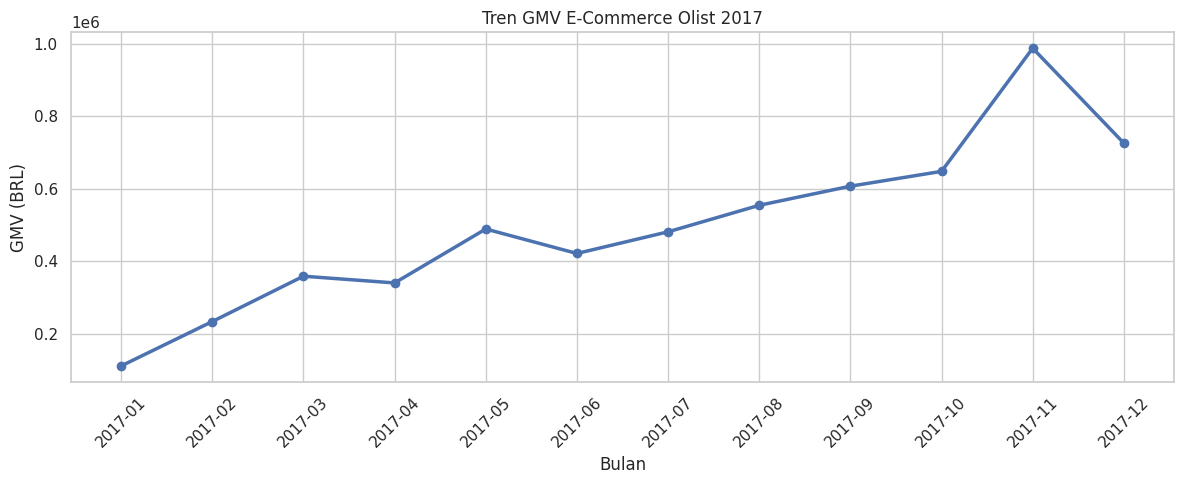

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    monthly["month"],
    monthly["gmv"],
    marker="o",
    linewidth=2.5
)

ax.set_title("Tren GMV E-Commerce Olist 2017")
ax.set_xlabel("Bulan")
ax.set_ylabel("GMV (BRL)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Selama Januari–Desember 2017, apa lima kategori produk dengan kontribusi GMV terbesar pada pesanan delivered, berapa persentase kontribusinya, dan bagaimana skor ulasan rata-ratanya untuk menentukan prioritas promosi serta perbaikan pengalaman pelanggan?

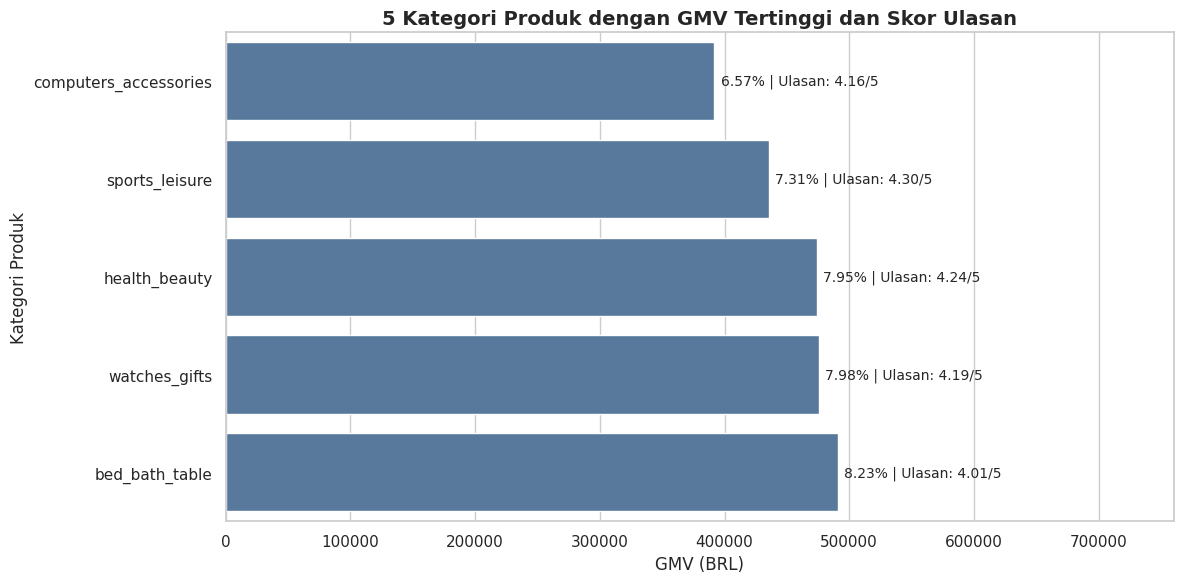

In [18]:
top5 = category_summary.nlargest(5, "gmv").copy()
top5 = top5.sort_values("gmv")

fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=top5,
    x="gmv",
    y="category",
    color="#4C78A8",
    ax=ax
)

# Menambahkan persentase kontribusi dan skor ulasan
for i, (_, row) in enumerate(top5.iterrows()):
    label = (
        f"{row['gmv_share_pct']:.2f}% | "
        f"Ulasan: {row['avg_review']:.2f}/5"
    )

    ax.text(
        row["gmv"] + 5000,
        i,
        label,
        va="center",
        fontsize=10
    )

ax.set_xlim(0, top5["gmv"].max() * 1.55)

ax.set_title(
    "5 Kategori Produk dengan GMV Tertinggi dan Skor Ulasan",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("GMV (BRL)")
ax.set_ylabel("Kategori Produk")

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- xxx
- xxx

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis E-Commerce Olist sepanjang Januari–Desember 2017, total GMV mencapai 5.962.902,01 BRL dari 43.428 pesanan berstatus delivered. Penjualan menunjukkan tren meningkat meskipun mengalami fluktuasi, dengan nilai tertinggi pada November sebesar 987.765,37 BRL atau meningkat 52,37% dibandingkan Oktober. Jumlah pesanan pada November juga mencapai 7.289 pesanan. Dengan demikian, November menjadi periode yang perlu diprioritaskan dalam perencanaan persediaan dan strategi promosi berdasarkan pola historis penjualan.

- **Conclusion pertanyaan 2:** Lima kategori produk dengan kontribusi GMV terbesar adalah bed_bath_table, watches_gifts, health_beauty, sports_leisure, dan computers_accessories, dengan kontribusi gabungan sebesar 38,03% dari total GMV. Kategori bed_bath_table memberikan kontribusi tertinggi sebesar 8,23%, tetapi memiliki rata-rata skor ulasan terendah di antara lima kategori tersebut, yaitu 4,01 dari skala 5. Sementara itu, sports_leisure memperoleh skor ulasan tertinggi sebesar 4,30. Hasil ini menunjukkan bahwa kontribusi penjualan yang tinggi tidak selalu diikuti skor ulasan pelanggan yang lebih tinggi.

**Rekomendasi Action Item:**
- **Optimalisasi persediaan:** Mengevaluasi kebutuhan stok dan kesiapan operasional menjelang periode dengan aktivitas penjualan tinggi, khususnya November berdasarkan pola historis.
- **Strategi promosi:** Memprioritaskan kegiatan pemasaran pada lima kategori dengan kontribusi GMV terbesar untuk mendukung kinerja penjualan.
- **Peningkatan pengalaman pelanggan:** Mengevaluasi kualitas produk, kesesuaian deskripsi, dan proses pengiriman pada kategori bed_bath_table yang memiliki skor ulasan relatif lebih rendah.
- **Monitoring kinerja:** Melakukan pemantauan GMV, jumlah pesanan, kontribusi kategori, dan skor ulasan secara berkala untuk mengevaluasi efektivitas tindakan yang diterapkan.